In [1]:
import os
import sys

current_path = os.path.abspath(os.getcwd())
base_path = os.path.abspath(os.path.join(current_path, '../../'))
sys.path.append(base_path)

from data_loader import DataLoader
import project_images_loader as pil

import tensorflow as tf

import discriminator as Discriminator
import generator as Generator

import util.functions as fc



2024-02-29 20:20:51.791359: I tensorflow/core/util/port.cc:113] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2024-02-29 20:20:51.831517: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-02-29 20:20:51.831549: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-02-29 20:20:51.832757: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-02-29 20:20:51.840194: I tensorflow/core/platform/cpu_feature_guar

Instructions for updating:
Call initializer instance with the dtype argument instead of passing it to the constructor


2024-02-29 20:20:54.238912: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1929] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 79086 MB memory:  -> device: 0, name: NVIDIA A100 80GB PCIe, pci bus id: 0000:8a:00.0, compute capability: 8.0


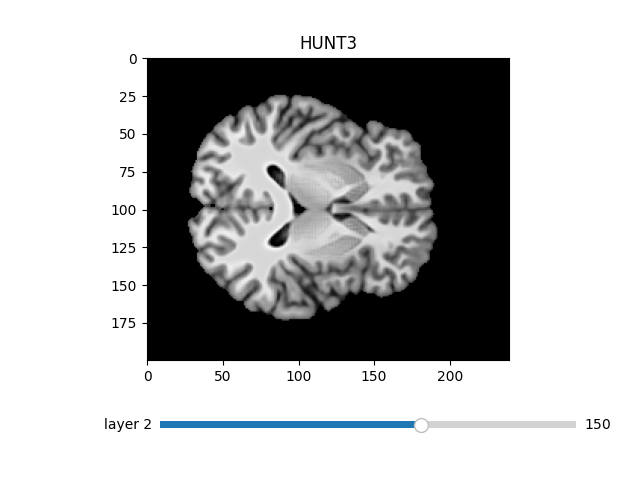

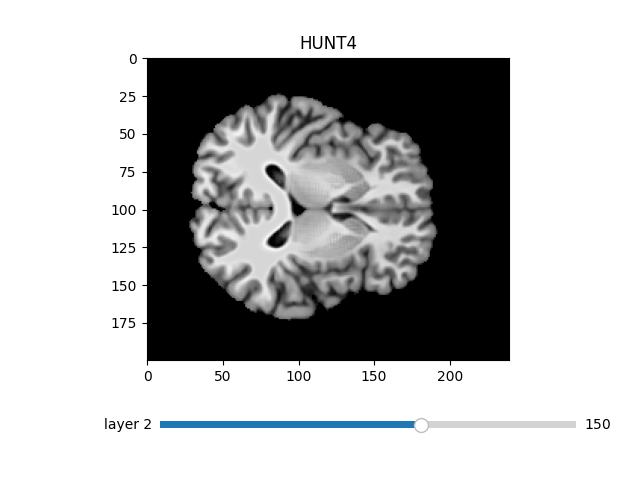

2024-02-29 20:20:56.242701: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:454] Loaded cuDNN version 8904
2024-02-29 20:20:56.319244: I external/local_tsl/tsl/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2024-02-29 20:20:57.147092: I external/local_tsl/tsl/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory


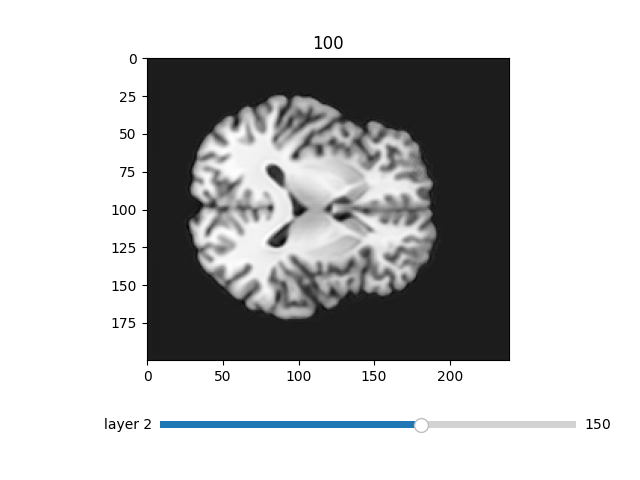

In [2]:
%matplotlib widget

input_shape = (200, 240, 240)

D = Discriminator.create_discriminator_model(input_shape)
G = Generator.create_generator_model(input_shape)

data_train = DataLoader(f"{pil.get_data_reduced_folder(absolute=True)}/train", batch_size=1, image_size=input_shape, shuffle=True, channels_first=False)
data = data_train[0]

fc.imgshow_3D(f"HUNT3", data[0][0,...,0], current_plane=150)
fc.imgshow_3D(f"HUNT4", data[1][0,...,0], current_plane=150)
# plot(data[1][0,...,0])
for epoch in range(100,101,10):
    G.load_weights(f"{current_path}/models/generator{epoch}.h5")
    img_generated = G(data[0])
    fc.imgshow_3D(f"{epoch}", img_generated[0,...,0], current_plane=150)
    # plot(img_generated[0,...,0])

